# Keşifsel Veri Analizi (EDA) · P3

Binance günlük OHLCV (BTC, ETH, SOL, BNB, XRP / USDT), Fear & Greed endeksi ve perpetual funding oranı.

- Veri: `uv run mindex fetch-data` ile üretilen Parquet anlık görüntüleri (`data/snapshots/`, SHA-256 manifestli).
- **Yalnızca eğitim dönemi (2020-09 → 2025-09) incelenir.** Doğrulama dönemi prompt/parametre ayarı için ayrılmıştır; test dönemi mühürlüdür ve bu notebook onu okumaz (look-ahead protokolü, [docs/04-ai-pipeline.md](../../docs/04-ai-pipeline.md)).

Çalıştırma: `cd backend && uv sync --group eda && uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01-eda.ipynb`

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

from mindex.data.snapshot import MANIFEST, load_split
from mindex.data.splits import Split
from mindex.domain.metrics import max_drawdown

SNAPSHOT = Path("../../data/snapshots").resolve()
train = load_split(SNAPSHOT, Split.TRAIN)
manifest = json.loads((SNAPSHOT / MANIFEST).read_text(encoding="utf-8"))
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 80, "axes.grid": True})
train.head()

asset,day,open,high,low,close,volume,fear_greed,funding_rate
str,date,f64,f64,f64,f64,f64,i16,f64
"""BNB""",2020-09-01,23.1481,25.41,22.84,24.7028,4442974.1,75,0.000758
"""BNB""",2020-09-02,24.7101,25.8262,23.1215,24.7652,5.8796e6,83,0.001031
"""BNB""",2020-09-03,24.7653,25.54,19.8765,20.3592,7.2313e6,79,0.00032
"""BNB""",2020-09-04,20.4027,21.83,19.2,20.9712,5.3062e6,40,-0.000031
"""BNB""",2020-09-05,20.9995,21.5539,18.011,19.4698,4.5892e6,41,-0.000446


## 1. Anlık görüntü ve veri kalitesi

In [2]:
pl.DataFrame(
    [
        {"split": k, **{f: v[f] for f in ("rows", "start", "end")}, "sha256": v["sha256"][:12]}
        for k, v in manifest["files"].items()
    ]
)

split,rows,start,end,sha256
str,i64,str,str,str
"""train""",9280,"""2020-09-01""","""2025-09-30""","""1713e703da67"""
"""validation""",910,"""2025-10-01""","""2026-03-31""","""dbd8580ffa38"""
"""test""",915,"""2026-04-01""","""2026-09-30""","""879a02b519ab"""


In [3]:
quality = manifest["quality"]
print("Eksik gün (varlık bazında):", quality["missing_days"] or "yok")
print("Fear & Greed boş satır:", quality["missing_fear_greed"])
print("Funding rate boş satır:", quality["missing_funding"])
train.group_by("asset").agg(
    pl.len().alias("gün"), pl.col("day").min().alias("ilk"), pl.col("day").max().alias("son")
).sort("asset")

Eksik gün (varlık bazında): yok
Fear & Greed boş satır: 5
Funding rate boş satır: 12


asset,gün,ilk,son
str,u32,date,date
"""BNB""",1856,2020-09-01,2025-09-30
"""BTC""",1856,2020-09-01,2025-09-30
"""ETH""",1856,2020-09-01,2025-09-30
"""SOL""",1856,2020-09-01,2025-09-30
"""XRP""",1856,2020-09-01,2025-09-30


## 2. Yıllık özet (DuckDB ile Parquet üzerinde SQL)

In [4]:
con = duckdb.connect()
cur = con.execute(
    """
    SELECT asset, year(day) AS yil,
           round(100 * (last(close ORDER BY day) / first(open ORDER BY day) - 1), 1) AS getiri_pct,
           round(avg(close * volume) / 1e6, 0) AS ort_hacim_musdt
    FROM read_parquet(?)
    GROUP BY ALL ORDER BY asset, yil
    """,
    [(SNAPSHOT / "train.parquet").as_posix()],
)
# fetchall keeps DuckDB independent of pyarrow
yearly = pl.DataFrame(cur.fetchall(), schema=[d[0] for d in cur.description], orient="row")
yearly.pivot(on="yil", index="asset", values="getiri_pct")

asset,2020,2021,2022,2023,2024,2025
str,f64,f64,f64,f64,f64,f64
"""BNB""",61.4,1268.9,-51.8,26.6,125.2,43.6
"""BTC""",148.3,59.8,-64.2,155.6,121.3,21.9
"""ETH""",69.8,399.2,-67.5,90.8,46.3,24.2
"""SOL""",-68.2,11166.6,-94.1,920.3,86.1,10.2
"""XRP""",-21.9,277.9,-59.2,81.6,238.5,36.6


## 3. Normalize fiyat (başlangıç = 1, log ölçek)

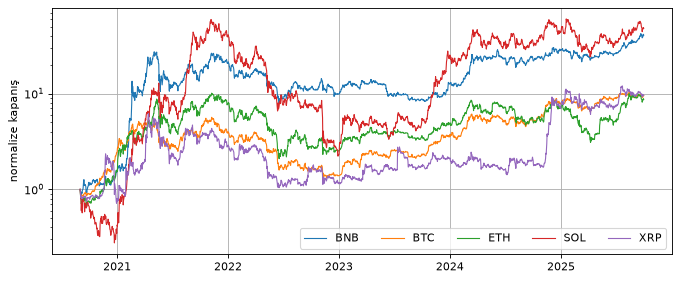

In [5]:
wide = train.pivot(on="asset", index="day", values="close").sort("day")
assets = [c for c in wide.columns if c != "day"]
fig, ax = plt.subplots()
for a in assets:
    ax.plot(wide["day"], wide[a] / wide[a][0], label=a, lw=1)
ax.set_yscale("log")
ax.set_ylabel("normalize kapanış")
ax.legend(ncol=5)
plt.show()

## 4. Günlük getiri dağılımı

In [6]:
rets = wide.select(
    "day", *[(pl.col(a) / pl.col(a).shift(1) - 1).alias(a) for a in assets]
).drop_nulls()
long = rets.unpivot(index="day", variable_name="asset", value_name="r")
stats = (
    long.group_by("asset")
    .agg(
        (pl.col("r").mean() * 100).round(3).alias("ort_pct"),
        (pl.col("r").std() * 100).round(2).alias("std_pct"),
        (pl.col("r").std() * 365**0.5 * 100).round(1).alias("yillik_vol_pct"),
        pl.col("r").skew().round(2).alias("carpiklik"),
        pl.col("r").kurtosis().round(1).alias("basiklik"),
        (pl.col("r").min() * 100).round(1).alias("min_pct"),
        (pl.col("r").max() * 100).round(1).alias("max_pct"),
    )
    .sort("asset")
)
stats

asset,ort_pct,std_pct,yillik_vol_pct,carpiklik,basiklik,min_pct,max_pct
str,f64,f64,f64,f64,f64,f64,f64
"""BNB""",0.296,4.49,85.7,2.49,39.8,-34.1,70.3
"""BTC""",0.17,3.11,59.4,0.15,3.6,-15.4,19.5
"""ETH""",0.204,4.18,79.9,0.19,4.8,-27.7,26.3
"""SOL""",0.406,6.32,120.7,0.59,6.4,-42.2,45.9
"""XRP""",0.279,5.78,110.4,2.52,27.8,-41.6,73.1


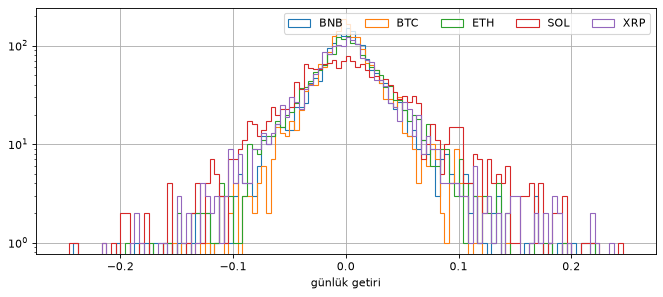

In [7]:
fig, ax = plt.subplots()
for a in assets:
    ax.hist(rets[a], bins=120, histtype="step", label=a, range=(-0.25, 0.25))
ax.set_yscale("log")
ax.set_xlabel("günlük getiri")
ax.legend(ncol=5)
plt.show()

## 5. Getiri korelasyonu (sürü riskinin piyasa kaynaklı tabanı)

In [8]:
corr = rets.select(assets).corr()
corr.insert_column(0, pl.Series("asset", assets)).with_columns(pl.col(assets).round(2))

asset,BNB,BTC,ETH,SOL,XRP
str,f64,f64,f64,f64,f64
"""BNB""",1.0,0.62,0.64,0.54,0.46
"""BTC""",0.62,1.0,0.8,0.56,0.53
"""ETH""",0.64,0.8,1.0,0.63,0.56
"""SOL""",0.54,0.56,0.63,1.0,0.46
"""XRP""",0.46,0.53,0.56,0.46,1.0


## 6. 30 günlük kayan volatilite ve maksimum düşüş

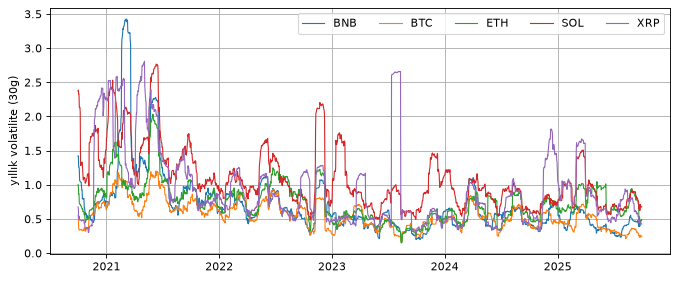

asset,mdd_pct
str,f64
"""BNB""",70.9
"""BTC""",76.6
"""ETH""",79.3
"""SOL""",96.3
"""XRP""",83.2


In [9]:
fig, ax = plt.subplots()
for a in assets:
    vol = rets[a].rolling_std(30) * 365**0.5
    ax.plot(rets["day"], vol, label=a, lw=1)
ax.set_ylabel("yıllık volatilite (30g)")
ax.legend(ncol=5)
plt.show()
pl.DataFrame(
    {"asset": assets, "mdd_pct": [round(max_drawdown(wide[a].to_list()) * 100, 1) for a in assets]}
)

## 7. Fear & Greed ve ertesi gün BTC getirisi

In [10]:
btc = (
    train.filter(pl.col("asset") == "BTC")
    .sort("day")
    .with_columns((pl.col("close").shift(-1) / pl.col("close") - 1).alias("next_r"))
    .drop_nulls(["next_r", "fear_greed"])
)
fg = pl.col("fear_greed")
band = (
    pl.when(fg <= 25)
    .then(pl.lit("1 aşırı korku"))
    .when(fg <= 45)
    .then(pl.lit("2 korku"))
    .when(fg <= 55)
    .then(pl.lit("3 nötr"))
    .when(fg <= 75)
    .then(pl.lit("4 açgözlülük"))
    .otherwise(pl.lit("5 aşırı açgözlülük"))
)
btc.with_columns(band.alias("bant")).group_by("bant").agg(
    pl.len().alias("gün"),
    (pl.col("next_r").mean() * 100).round(3).alias("ertesi_gun_ort_pct"),
    (pl.col("next_r").std() * 100).round(2).alias("std_pct"),
).sort("bant")

bant,gün,ertesi_gun_ort_pct,std_pct
str,u32,f64,f64
"""1 aşırı korku""",305,0.037,3.84
"""2 korku""",381,0.118,3.2
"""3 nötr""",338,0.057,2.4
"""4 açgözlülük""",591,0.244,2.46
"""5 aşırı açgözlülük""",239,0.395,4.11


## 8. Funding oranı

In [11]:
train.group_by("asset").agg(
    (pl.col("funding_rate").mean() * 100).round(4).alias("ort_pct_8s"),
    (pl.col("funding_rate") > 0).mean().round(2).alias("pozitif_oran"),
    (pl.col("funding_rate").max() * 100).round(3).alias("max_pct"),
    (pl.col("funding_rate").min() * 100).round(3).alias("min_pct"),
).sort("asset")

asset,ort_pct_8s,pozitif_oran,max_pct,min_pct
str,f64,f64,f64,f64
"""BNB""",-0.0011,0.3,0.321,-0.226
"""BTC""",0.0115,0.9,0.162,-0.085
"""ETH""",0.0129,0.89,0.252,-0.176
"""SOL""",0.0044,0.75,0.267,-1.561
"""XRP""",0.014,0.84,0.29,-0.32


## Bulgular

1. **Veri eksiksiz.** Beş varlığın her biri için eğitim döneminde 1856 günün tamamı var; mum boşluğu yok. Fear & Greed'de 5, funding oranında 12 boş satır var; ajan gözleminde bunlar `null` olarak geçer.
2. **Rejimler çok belirgin.** 2021 boğa (SOL ×112), 2022 ayı (tüm varlıklar −%52…−%94), 2023–2024 toparlanma. Eğitim dönemi üç rejimi de içerir; bu, P4'teki HMM rejim modeli için yeterli çeşitlilik demek.
3. **Kalın kuyruklar.** Yıllık volatilite %59 (BTC) ile %121 (SOL) arasında; BNB ve XRP'de basıklık 28–40, tek günde +%70'e varan sıçramalar var. Getiriler normal dağılmıyor. Bu yüzden Sharpe'ın yanında MDD de raporlanıyor ve farklar blok bootstrap ile test edilecek.
4. **Varlıklar birlikte hareket ediyor.** Günlük getiri korelasyonu 0,46–0,80 (BTC–ETH 0,80). LLM ajanları arasında ölçülecek sürü korelasyonunun önemli bir kısmı piyasanın kendisinden gelir. Bu taban, kural tabanlı ajanların korelasyonuyla karşılaştırılarak raporlanmalıdır.
5. **Maksimum düşüş çok büyük.** Al-ve-tut MDD'si %71 (BNB) ile %96 (SOL) arasında; BTC'de %77. "En iyi LLM ajanında BTC al-ve-tut'a göre ≥ %30 daha düşük MDD" hedefi, nakde geçebilen bir ajan için ulaşılabilir görünüyor.
6. **Duyarlılık sinyali zayıf.** BTC'de açgözlülük bantlarında ertesi gün ortalama getirisi daha yüksek (+%0,24 / +%0,40), korku bantlarında daha düşük. Ancak günlük std %2,4–4,1 ve bant başına 239–591 gün olduğundan standart hata ≈ %0,15–0,27; farklar istatistiksel olarak zayıf. Duyarlılık ajanı için tek başına güçlü bir sinyal değil.
7. **Funding çoğunlukla pozitif.** BTC/ETH'de günlerin %89–90'ında pozitif; uç değerler (SOL −%1,56) kalabalık pozisyonların tasfiyesini gösteriyor. Bu oran, duyarlılık ajanına yalnızca gözlem özelliği olarak verilir.
